## Data Cleaning and Quality Assessment
## Homework 6 - Value Imputation
## Hadi Seyed

### Setup

In [2]:
# # pip -q install pandas, numpy, matplotlib, scikit-learn, and imbalanced-learn.

import io, urllib.request, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.ensemble import ExtraTreesRegressor, RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, accuracy_score, classification_report
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from imblearn.over_sampling import SMOTE, ADASYN
SEED=42
def getdata(url):
    req=urllib.request.Request(url, headers={"User-Agent":"Mozilla/5.0"})
    return urllib.request.urlopen(req, timeout=60).read()
def rmsd(a,b):
    return float(np.sqrt(np.mean((np.asarray(a)-np.asarray(b))**2)))

### Question 1 - Alternate Trend Imputation

The kryptonite data contain laser wavelength, kryptonite type, and measured luminance (`candela_per_m2`). Convert wavelength to laser frequency as in the textbook. Fit polynomial models by kryptonite type using only observed luminance values.

In [3]:
url="https://www.gnosis.cx/cleaning/excited-kryptonite.fwf"
k=pd.read_fwf(io.BytesIO(getdata(url)))
display(k.head()); print(k.columns.tolist(), k.shape)
# Derive frequency (Hz) from wavelength (nm).
k["Frequency_hz"]=299_792_458/(k["Wavelength_nm"]*1e-9)
k=k.sort_values(["Kryptonite_type","Frequency_hz"]).reset_index(drop=True)
display(k.groupby("Kryptonite_type")["candela_per_m2"].agg(["count","size"]))

,Laser_type_kw,Subtype,Wavelength_nm,Kryptonite_type,candela_per_m2
0,Helium–neon,NaN,632.8,Green,415.837
1,Helium–neon,NaN,543.5,Green,NaN
2,Helium–neon,NaN,593.9,Green,407.308
3,Helium–neon,NaN,611.8,Green,401.305
4,Helium–neon,NaN,1152.3,Green,426.012


['Laser_type_kw', 'Subtype', 'Wavelength_nm', 'Kryptonite_type', 'candela_per_m2'] (99, 5)


,count,size
Kryptonite_type,,
Gold,26,33
Green,24,33
Red,24,33


#### Polynomial, nonlinear regression, local interpolation, and forward-fill comparisons

Comparison,All points vs poly2,Missing only: ExtraTrees vs poly2,Missing only: Forward fill vs poly2,Missing only: Local interpolation vs poly2,Missing only: poly1 vs poly2,Missing only: poly2 vs poly2,Missing only: poly3 vs poly2,Observed vs ExtraTrees,Observed vs poly1,Observed vs poly2,Observed vs poly3
Type,,,,,,,,,,,
Gold,7.5253,1.4261,8.3212,4.3854,0.6862,0.0,2.1970,7.9924,8.5060,8.4781,8.3357
Green,11.6867,16.5454,16.6289,15.0259,41.8223,0.0,39.1508,12.4256,22.4785,13.7039,11.9473
Red,18.5267,24.3900,19.7855,18.6644,67.2166,0.0,64.0225,17.8468,41.3512,21.7245,18.4366


,Comparison,RMSD
0,poly1 vs poly2 (missing only),47.5007
1,poly2 vs poly2 (missing only),0.0000
2,poly3 vs poly2 (missing only),45.0417
3,ExtraTrees vs poly2 (missing only),17.6996
4,Local interpolation vs poly2 (missing only),14.5628
5,Forward fill vs poly2 (missing only),16.1203


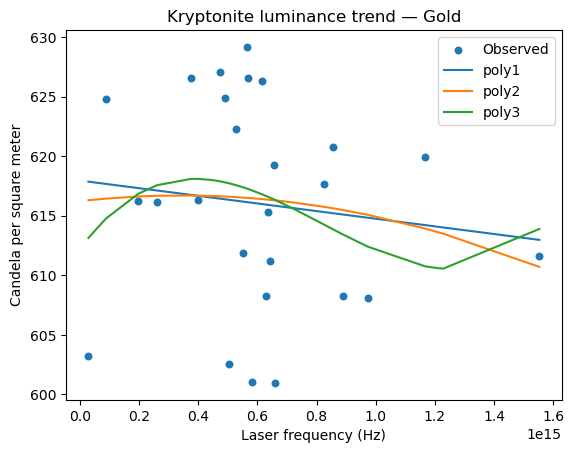

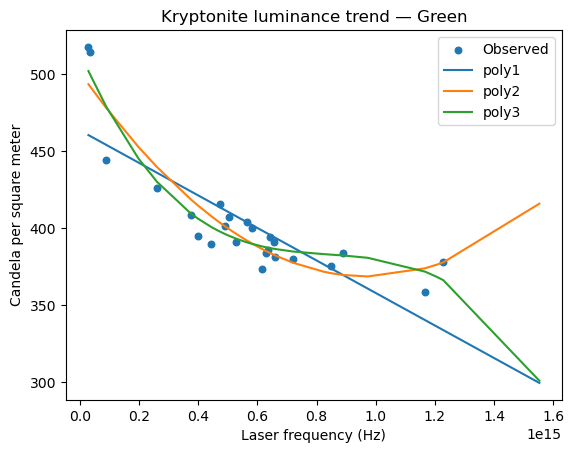

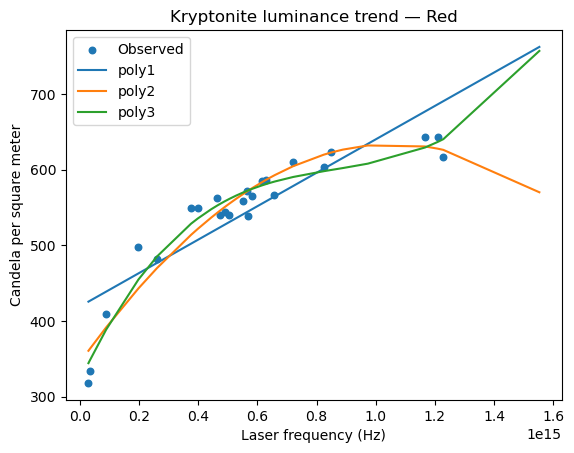

In [9]:
def fit_group(g):
    g=g.sort_values("Frequency_hz").copy()
    obs=g["candela_per_m2"].notna()
    miss=~obs
    x=g["Frequency_hz"].to_numpy()
    
    # # Scale x to avoid numerical instability in polynomial fitting.
    center=x[obs].mean(); scale=x[obs].std()
    z=(x-center)/(scale if scale else 1)
    y=g.loc[obs,"candela_per_m2"].to_numpy()
    predictions={}
    for d in (1,2,3):
        coef=np.polyfit(z[obs],y,d)
        predictions[f"poly{d}"]=np.polyval(coef,z)
    et=ExtraTreesRegressor(n_estimators=300,min_samples_leaf=2,random_state=SEED)
    et.fit(z[obs].reshape(-1,1),y)
    predictions["ExtraTrees"]=et.predict(z.reshape(-1,1))
    predictions["Local interpolation"]=g["candela_per_m2"].interpolate(limit_direction="both").to_numpy()
    predictions["Forward fill"]=g["candela_per_m2"].ffill().bfill().to_numpy()
    rows=[]
    
    # # Compare observed measurements with each fitted regression on observed positions.
    for name,p in predictions.items():
        if name in ("Local interpolation","Forward fill"): continue
        rows.append({"Type":g["Kryptonite_type"].iloc[0],
                     "Comparison":f"Observed vs {name}","RMSD":rmsd(y,p[obs])})
        
    # # Compare imputed values only against the quadratic reference.
    for name,p in predictions.items():
        rows.append({"Type":g["Kryptonite_type"].iloc[0],
                     "Comparison":f"Missing only: {name} vs poly2",
                     "RMSD":rmsd(p[miss],predictions["poly2"][miss]) if miss.any() else np.nan})
        
    # # RMSD of all original + imputed values against the quadratic curve.
    # rows.append({"Type":g["Kryptonite_type"].iloc[0],
    #              "Comparison":"All points vs poly2","RMSD":rmsd(
    #                  g["candela_per_m2"].fillna(predictions["poly2"])[~g["candela_per_m2"].isna() | miss],
    #                  predictions["poly2"][~g["candela_per_m2"].isna() | miss])})
    
    observed_or_imputed = np.where(
        g["candela_per_m2"].isna(),
        predictions["poly2"],
        g["candela_per_m2"].to_numpy()
    )

    rows.append({
        "Type": g["Kryptonite_type"].iloc[0],
        "Comparison": "All points vs poly2",
        "RMSD": rmsd(
            observed_or_imputed,
            predictions["poly2"]
        )
    })
    return pd.DataFrame(rows),predictions,g
allrows=[]; fits={}
for typ,g in k.groupby("Kryptonite_type"):
    r,p,gg=fit_group(g); allrows.append(r); fits[typ]=(p,gg)
q1=pd.concat(allrows,ignore_index=True)
display(q1.pivot(index="Type",columns="Comparison",values="RMSD").round(4))

# # Pooled RMSD across all colors for each imputation strategy vs quadratic fit.
pool=[]
for name in ["poly1","poly2","poly3","ExtraTrees","Local interpolation","Forward fill"]:
    a=[]; b=[]
    for typ,(p,g) in fits.items():
        m=g["candela_per_m2"].isna().to_numpy()
        a.extend(p[name][m]); b.extend(p["poly2"][m])
    pool.append({"Comparison":f"{name} vs poly2 (missing only)","RMSD":rmsd(a,b)})
display(pd.DataFrame(pool).round(4))
for typ,(p,g) in fits.items():
    plt.figure()
    plt.scatter(g.loc[g.candela_per_m2.notna(),"Frequency_hz"],
                g.loc[g.candela_per_m2.notna(),"candela_per_m2"],label="Observed",s=22)
    for name in ["poly1","poly2","poly3"]:
        plt.plot(g.Frequency_hz,p[name],label=name)
    plt.title(f"Kryptonite luminance trend — {typ}")
    plt.xlabel("Laser frequency (Hz)"); plt.ylabel("Candela per square meter")
    plt.legend()
    plt.show()

#### Interpretation

Use the RMSD table and plots to compare the methods. Lower RMSD means closer agreement with the quadratic reference, not proof of accuracy: the missing values have no known ground truth. Polynomial degree 2 is the textbook baseline; local interpolation uses neighboring observations, while forward-fill assumes the previous value remains unchanged. ExtraTrees provides a flexible nonlinear comparison. A reasonable recommendation is the method that has low missing-point RMSD without producing implausible curves; explain any color-specific differences using the plots.

### Question 2 - Balancing Multiple Features

Load the height/weight/favorite-color data, calculate BMI, and divide Height, Weight, and BMI independently into five equal-width ranges. The goal is to balance each marginal feature without chaining three fourfold expansions.

In [10]:
u="https://www.gnosis.cx/cleaning/height-weight-color.csv"
h=pd.read_csv(io.BytesIO(getdata(u)))
h=h.dropna(subset=["Height","Weight","Favorite"]).copy()
h["BMI"]=h["Weight"]/(h["Height"]/100)**2
features=["Height","Weight","BMI"]
edges={c:np.linspace(h[c].min(),h[c].max(),6) for c in features}
def labels(df,c):
    return pd.cut(df[c],bins=edges[c],include_lowest=True)
for c in features:
    print(c); display(labels(h,c).value_counts().sort_index())

Height


Height
(153.106, 160.663]      145
(160.663, 168.219]     4251
(168.219, 175.776]    14050
(175.776, 183.332]     6229
(183.332, 190.888]      325
Name: count, dtype: int64

Weight


Weight
(44.744, 55.402]      125
(55.402, 66.06]      3708
(66.06, 76.717]     14074
(76.717, 87.375]     6700
(87.375, 98.033]      393
Name: count, dtype: int64

BMI


BMI
(16.526, 19.803]      235
(19.803, 23.079]     5849
(23.079, 26.354]    14813
(26.354, 29.63]      3993
(29.63, 32.906]       110
Name: count, dtype: int64

#### Method A - Independent duplication of underrepresented bins

In [11]:
def duplicate_for_feature(df,feature,seed=SEED):
    lab=labels(df,feature); counts=lab.value_counts().sort_index()
    target=int(counts.max()); parts=[df]
    rng=np.random.default_rng(seed)
    for category,n in counts.items():
        subset=df.loc[lab==category]
        if len(subset) and n<target:
            idx=rng.choice(subset.index.to_numpy(),target-n,replace=True)
            parts.append(df.loc[idx])
    return pd.concat(parts,ignore_index=True)
    
# # Each operation starts from the original data; concatenate additions once.
dup_parts=[h]
for i,c in enumerate(features):
    extra=duplicate_for_feature(h,c,SEED+i).iloc[len(h):]
    dup_parts.append(extra)
dup=pd.concat(dup_parts,ignore_index=True)
print("Original rows:",len(h),"Independent-duplication rows:",len(dup))
for c in features:
    print(c); display(labels(dup,c).value_counts().sort_index())

Original rows: 25000 Independent-duplication rows: 164685
Height


Height
(153.106, 160.663]    17181
(160.663, 168.219]    39551
(168.219, 175.776]    56194
(175.776, 183.332]    35295
(183.332, 190.888]    16464
Name: count, dtype: int64

Weight


Weight
(44.744, 55.402]    20436
(55.402, 66.06]     38915
(66.06, 76.717]     37883
(76.717, 87.375]    43679
(87.375, 98.033]    23772
Name: count, dtype: int64

BMI


BMI
(16.526, 19.803]    23741
(19.803, 23.079]    40259
(23.079, 26.354]    46982
(26.354, 29.63]     36990
(29.63, 32.906]     16713
Name: count, dtype: int64

#### Method B - SMOTE and ADASYN

For each feature, use its five-bin label as the temporary class target and the other two numeric measurements as predictors. Generate synthetic values, assign the bin midpoint for the balanced feature, and assign Favorite from the nearest original observation in standardized Height/Weight/BMI space. This keeps the nominal label grounded in an observed neighbor. SMOTE and ADASYN can fail if a bin has too few observations. Change "SMOTE" to "ADASYN" and vice versa to compare the alternative.

In [14]:
def synthesize_one_feature(df,feature,algorithm="SMOTE",seed=SEED):
    other=[c for c in features if c!=feature]
    y=pd.cut(df[feature],bins=edges[feature],labels=False,include_lowest=True)
    X=df[other].astype(float)
    min_n=int(y.value_counts().min())
    if min_n<2: raise ValueError("A bin has fewer than two records.")
    sampler=(SMOTE(random_state=seed,k_neighbors=min(5,min_n-1)) if algorithm=="SMOTE"
             else ADASYN(random_state=seed,n_neighbors=min(5,min_n-1)))
    Xr,yr=sampler.fit_resample(X,y)
    nnew=len(Xr)-len(df)
    if nnew<=0: return df.iloc[:0].copy()
    newx=np.asarray(Xr)[len(df):]; newy=np.asarray(yr)[len(df):].astype(int)
    syn=pd.DataFrame(np.nan,index=range(nnew),columns=df.columns)
    for j,c in enumerate(other): syn[c]=newx[:,j]
    syn[feature]=(edges[feature][newy]+edges[feature][newy+1])/2
    scaler=StandardScaler().fit(df[features])
    knn=KNeighborsClassifier(n_neighbors=1).fit(scaler.transform(df[features]),df.Favorite)
    temp=syn[features].astype(float).fillna(df[features].median())
    syn["Favorite"]=knn.predict(scaler.transform(temp))
    return syn[df.columns]
method="SMOTE"   # # Change to "ADASYN" to compare the alternative.
pieces=[h]
for i,c in enumerate(features):
    try:
        pieces.append(synthesize_one_feature(h,c,method,SEED+i))
    except Exception as e:
        print(c,method,"could not be applied:",e)
synthetic=pd.concat(pieces,ignore_index=True)
print(method,"combined rows:",len(synthetic))
for c in features:
    print(c); display(labels(synthetic,c).value_counts().sort_index())

SMOTE combined rows: 164685
Height


Height
(153.106, 160.663]    17073
(160.663, 168.219]    39851
(168.219, 175.776]    56095
(175.776, 183.332]    35175
(183.332, 190.888]    16491
Name: count, dtype: int64

Weight


Weight
(44.744, 55.402]    20444
(55.402, 66.06]     38841
(66.06, 76.717]     38073
(76.717, 87.375]    43614
(87.375, 98.033]    23713
Name: count, dtype: int64

BMI


BMI
(16.526, 19.803]    23295
(19.803, 23.079]    40452
(23.079, 26.354]    47523
(26.354, 29.63]     36614
(29.63, 32.906]     16801
Name: count, dtype: int64

#### Reduce to approximately 100,000 rows and check the balance requirement

In [15]:
# # Weighted sampling without replacement; repeatedly favor bins that are currently scarce.

def reduce_balanced(df,n=100_000,seed=SEED):
    rng=np.random.default_rng(seed)
    if len(df)<=n: return df.copy()
    work=df.reset_index(drop=True).copy()
    bincols={c:pd.cut(work[c],bins=edges[c],labels=False,include_lowest=True) for c in features}
    chosen=[]; counts={c:np.zeros(5,dtype=int) for c in features}
    for _ in range(n):
        w=np.ones(len(work),dtype=float)
        for c in features:
            b=bincols[c].to_numpy()
            w*=1/(counts[c][b]+1)
        w/=w.sum()
        ix=int(rng.choice(len(work),p=w))
        chosen.append(ix)
        for c in features: counts[c][int(bincols[c].iloc[ix])]+=1
            
        # # Remove selected row to sample without replacement.
        work=work.drop(index=ix).reset_index(drop=True)
        bincols={c:pd.cut(work[c],bins=edges[c],labels=False,include_lowest=True) for c in features}
    return df.reset_index(drop=True).iloc[chosen].reset_index(drop=True)
reduced=reduce_balanced(synthetic,min(100_000,len(synthetic)))
print("Reduced dataset rows:",len(reduced))
for c in features:
    ct=pd.cut(reduced[c],bins=edges[c],include_lowest=True).value_counts().sort_index()
    gap=(ct.max()-ct.min())/ct.mean()*100
    print(c,"counts:",ct.tolist(),"max-min difference (% of mean):",round(gap,2))
    print("Requirement <25%:",gap<25)
    
# # Save the synthetic dataset for inspection.
reduced.to_csv("balanced_height_weight_bmi.csv",index=False)

Reduced dataset rows: 100000
Height counts: [16150, 24095, 24568, 20707, 14480] max-min difference (% of mean): 50.44
Requirement <25%: False
Weight counts: [14052, 23195, 29285, 24220, 9248] max-min difference (% of mean): 100.18
Requirement <25%: False
BMI counts: [11000, 27140, 40788, 19125, 1947] max-min difference (% of mean): 194.2
Requirement <25%: False


#### Interpretation

Compare the original, duplicated, and synthetic bin counts for all three features. Duplication is easy to explain but repeats observations and may increase overfitting. SMOTE/ADASYN create new numeric combinations, but synthetic values and nearest-neighbor Favorite labels are approximations. The final output explicitly checks whether each feature's maximum-to-minimum bin-count difference is below 25% of the mean. If any check is False, the target has not yet been achieved and the sampling strategy must be adjusted.

### Extra Credit - Predict Favorite Color

Train a Random Forest classifier using Height, Weight, and BMI. Evaluate on a stratified test set, report accuracy, class metrics, feature importance, and example probability predictions.

Test accuracy: 0.56
              precision    recall  f1-score   support

        blue       0.66      0.74      0.69      1991
       green       0.33      0.18      0.23      1865
         red       0.56      0.71      0.63      2394

    accuracy                           0.56      6250
   macro avg       0.52      0.54      0.52      6250
weighted avg       0.52      0.56      0.53      6250



,importance
BMI,0.454345
Weight,0.307417
Height,0.238239


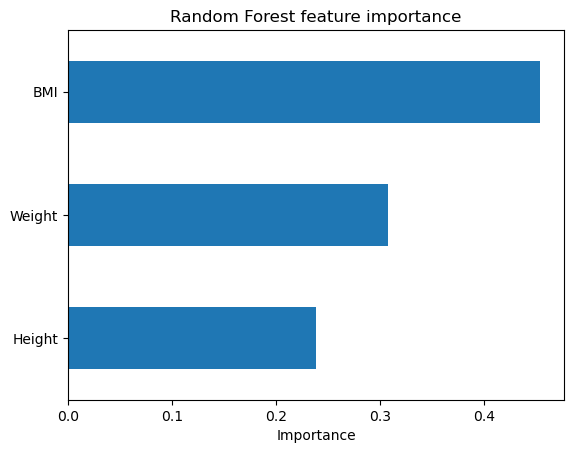

,Height,Weight,BMI,blue,green,red
0,160,55,21.484375,0.081152,0.431349,0.487498
1,170,70,24.221453,0.078713,0.273360,0.647927
2,180,85,26.234568,0.561817,0.203408,0.234775


In [16]:
X=h[features]; y=h["Favorite"].astype(str)
Xtr,Xte,ytr,yte=train_test_split(X,y,test_size=.25,random_state=SEED,stratify=y)
model=RandomForestClassifier(n_estimators=400,min_samples_leaf=5,
                             class_weight="balanced",random_state=SEED)
model.fit(Xtr,ytr); pred=model.predict(Xte)
print("Test accuracy:",round(accuracy_score(yte,pred),4))
print(classification_report(yte,pred))
importance=pd.Series(model.feature_importances_,index=features).sort_values(ascending=False)
display(importance.to_frame("importance"))
importance.sort_values().plot.barh(title="Random Forest feature importance")
plt.xlabel("Importance"); plt.show()
example=pd.DataFrame({"Height":[160,170,180],"Weight":[55,70,85]})
example["BMI"]=example.Weight/(example.Height/100)**2
display(pd.concat([example,pd.DataFrame(model.predict_proba(example),columns=model.classes_)],axis=1))

#### Interpretation

Report the actual holdout accuracy and the strongest feature from the executed output. Feature importance describes how the fitted model uses the inputs; it does not show causation. The source says Favorite was generated roughly at random but includes some embedded pattern, so interpret model performance cautiously.